# Tahap 6 KDD - Prediksi Foto Baru

Demo `src.predict.predict_image` pada beberapa foto data uji. Fungsi ini memakai preprocessing dan ekstraksi fitur yang sama dengan saat pelatihan.

In [1]:
%matplotlib inline
import os, sys
from pathlib import Path

HERE = Path.cwd().resolve()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import config as C

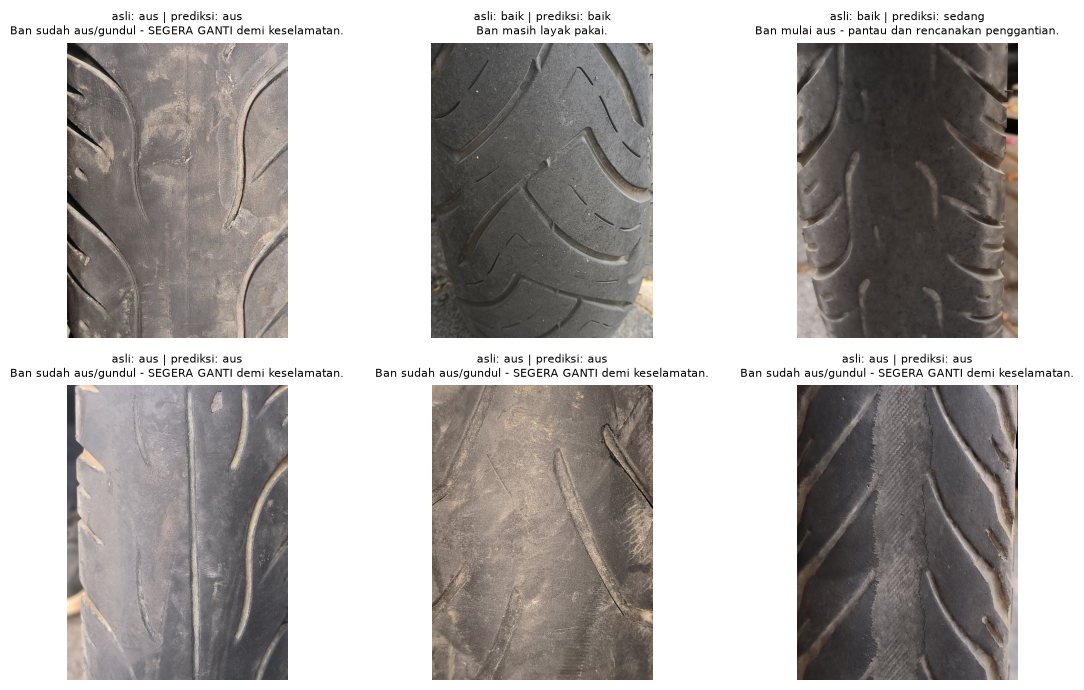

In [2]:
import cv2
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from src.predict import predict_image

bundle = joblib.load(C.MODELS_DIR / "best_model.joblib")
splits = pd.read_csv(C.PROCESSED_DIR / "splits.csv")
test = splits[splits["split"] == "test"].sample(6, random_state=C.RANDOM_STATE)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (_, r) in zip(axes.ravel(), test.iterrows()):
    img = cv2.imread(r["path"])
    result = predict_image(r["path"], bundle=bundle)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.axis("off")
    ax.set_title(f"asli: {r['label']} | prediksi: {result['label']}\n{result['pesan']}", fontsize=8)
plt.tight_layout()
plt.show()

In [3]:
print("Prediksi satu foto via CLI:")
print(f"python -m src.predict \"{test.iloc[0]['path']}\"")

Prediksi satu foto via CLI:
python -m src.predict "D:\Perkuliahan\Machine Learning teori\Ban_Motor\data\raw\aus\ban_aus_75.jpg"
